In [12]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mitchellharrison/my-first-1000-valorant-games/valorant_games.csv


In [4]:
path = '/kaggle/input/datasets/mitchellharrison/my-first-1000-valorant-games/valorant_games.csv'

df = pd.read_csv(path)

df.head(10)

,game_id,episode,act,rank,date,agent,map,outcome,round_wins,round_losses,kills,deaths,assists,kdr,avg_dmg_delta,headshot_pct,avg_dmg,acs,num_frag
0,1,6,2,Placement,4/11/2023,Cypher,Ascent,Loss,5,13,8,15,4,0.5,-61,3,76,125,3
1,2,6,2,Placement,4/12/2023,Cypher,Icebox,Loss,4,13,3,15,2,0.2,-124,22,42,59,5
2,3,6,2,Placement,4/15/2023,KAY/O,Lotus,Win,13,4,7,12,7,0.6,-46,2,87,132,5
3,4,6,2,Placement,4/15/2023,Brimstone,Ascent,Loss,9,13,18,12,10,1.5,23,14,137,230,2
4,5,6,2,Placement,4/15/2023,Cypher,Haven,Loss,1,13,6,14,3,0.4,-75,7,90,146,4
5,6,6,2,Silver 2,4/15/2023,KAY/O,Haven,Win,13,10,16,15,18,1.1,19,10,155,234,3
6,7,6,2,Silver 2,4/15/2023,Cypher,Pearl,Loss,3,13,7,15,5,0.5,-43,11,112,145,4
7,8,6,2,Silver 2,4/15/2023,KAY/O,Icebox,Loss,4,13,8,15,4,0.5,-70,3,73,119,5
8,9,6,2,Silver 2,4/16/2023,Cypher,Pearl,Loss,10,13,14,17,4,0.8,-32,9,99,160,4
9,10,6,2,Silver 2,4/16/2023,Phoenix,Fracture,Win,13,4,16,7,6,2.3,111,8,211,284,2


In [5]:
# Number of rows and columns
print(df.shape)

(1000, 19)


In [6]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   game_id        1000 non-null   int64  
 1   episode        1000 non-null   int64  
 2   act            1000 non-null   int64  
 3   rank           1000 non-null   object 
 4   date           1000 non-null   object 
 5   agent          1000 non-null   object 
 6   map            1000 non-null   object 
 7   outcome        1000 non-null   object 
 8   round_wins     1000 non-null   int64  
 9   round_losses   1000 non-null   int64  
 10  kills          1000 non-null   int64  
 11  deaths         1000 non-null   int64  
 12  assists        1000 non-null   int64  
 13  kdr            1000 non-null   float64
 14  avg_dmg_delta  1000 non-null   int64  
 15  headshot_pct   1000 non-null   int64  
 16  avg_dmg        1000 non-null   int64  
 17  acs            1000 non-null   int64  
 18  num_frag 

In [7]:
# Summary statistics for numerical columns
df.describe()

,game_id,episode,act,round_wins,round_losses,kills,deaths,assists,kdr,avg_dmg_delta,headshot_pct,avg_dmg,acs,num_frag
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,7.500000,2.066000,10.589000,10.52700,15.299000,14.249000,4.656000,1.178400,10.308000,22.763000,134.446000,205.382000,2.990000
std,288.819436,1.102368,0.868561,3.359966,3.55273,5.253113,3.724362,2.656072,0.656784,43.383791,9.919033,35.199916,56.539958,1.368127
min,1.000000,6.000000,1.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.200000,-124.000000,2.000000,42.000000,59.000000,1.000000
25%,250.750000,7.000000,1.000000,8.000000,8.00000,12.000000,13.000000,3.000000,0.800000,-20.000000,15.000000,110.000000,166.000000,2.000000
50%,500.500000,7.000000,2.000000,13.000000,13.00000,15.000000,15.000000,4.000000,1.100000,9.000000,22.000000,133.000000,203.000000,3.000000
75%,750.250000,9.000000,3.000000,13.000000,13.00000,19.000000,17.000000,6.000000,1.400000,39.000000,29.000000,157.000000,240.000000,4.000000
max,1000.000000,9.000000,3.000000,18.000000,20.00000,35.000000,26.000000,20.000000,9.700000,293.000000,63.000000,373.000000,572.000000,5.000000


# 1. Data cleaning
There's no cleaning needed for now, dataset too good

# 2. Problem Statement: What agents should you pick to keep winning

# 3. Visualizing

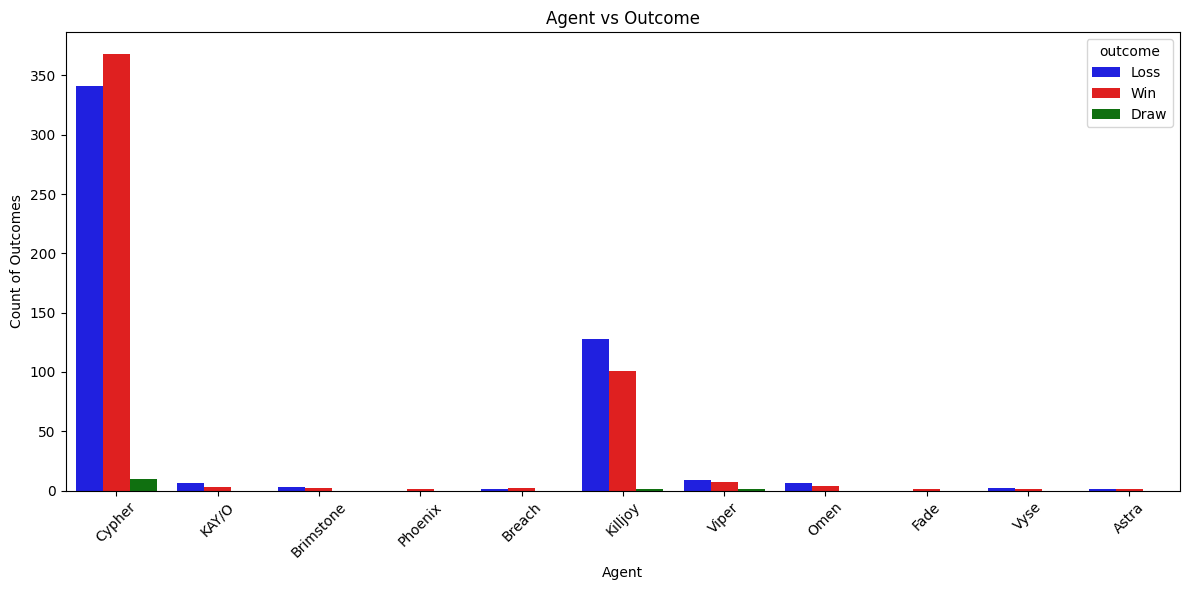

In [38]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='agent',
    hue='outcome',
    palette={'Loss': 'blue',
            'Win': 'red',
            'Draw': 'green'
            }
)

plt.xlabel('Agent')
plt.ylabel('Count of Outcomes')
plt.title('Agent vs Outcome')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Hmmmm for now it just shows that you like playing Cypher and Killjoy doesn't mean the winrate is high

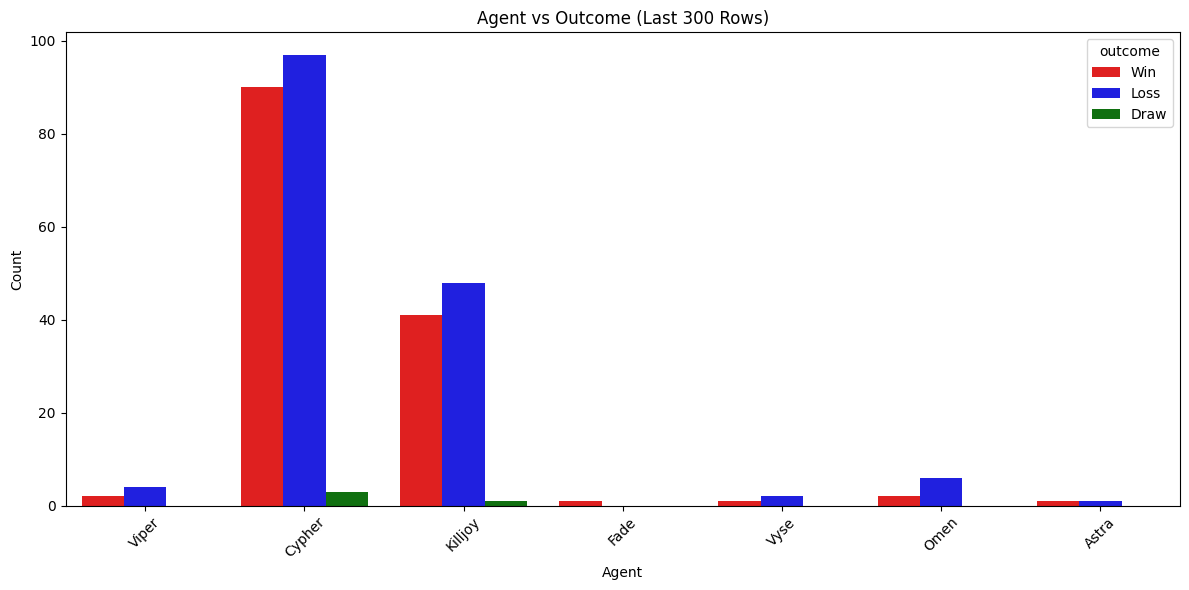

In [42]:
df_tail = df.tail(300)

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_tail,
    x='agent',
    hue='outcome',
    palette={'Loss': 'blue',
            'Win': 'red',
            'Draw': 'green'
            }
)

plt.xlabel('Agent')
plt.ylabel('Count')
plt.title('Agent vs Outcome (Last 300 Rows)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# I'm taking the last 300 matches because those are the high elo matches. You  still enjoyed playing Cypher and Killjoy

<Figure size 1200x600 with 0 Axes>

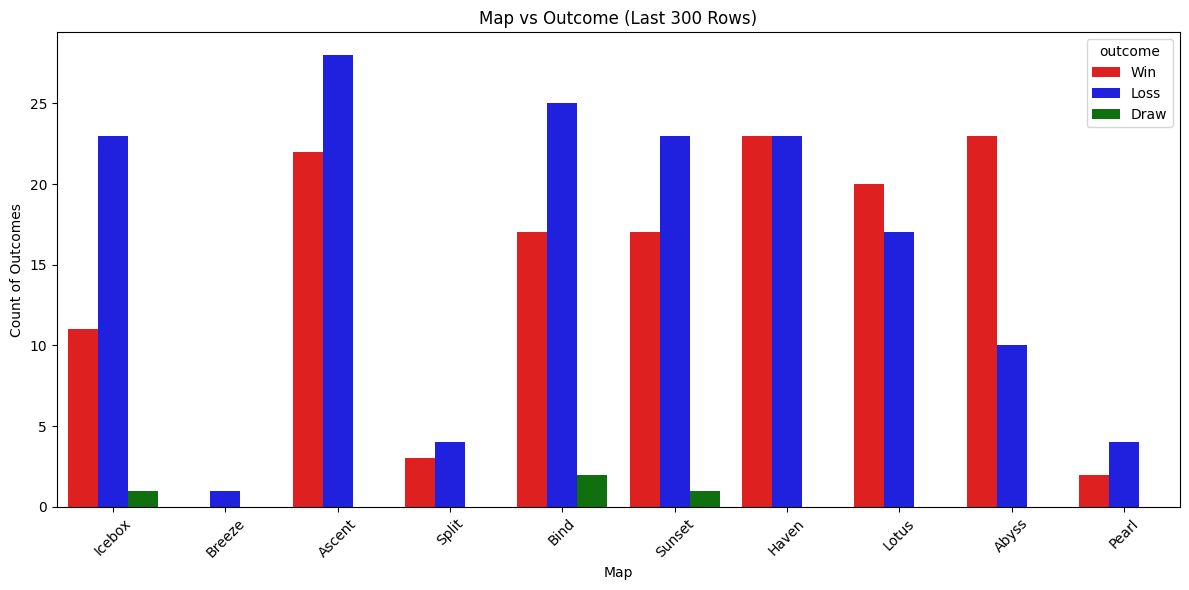

In [44]:
df_tail = df.tail(300)

plt.figure(figsize=(12, 6))

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_tail,
    x='map',
    hue='outcome',
    palette={'Loss': 'blue',
            'Win': 'red',
            'Draw': 'green'
            }
)

plt.xlabel('Map')
plt.ylabel('Count of Outcomes')
plt.title('Map vs Outcome (Last 300 Rows)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Your winrate for map Haven, Lotus, Abyss is pretty high

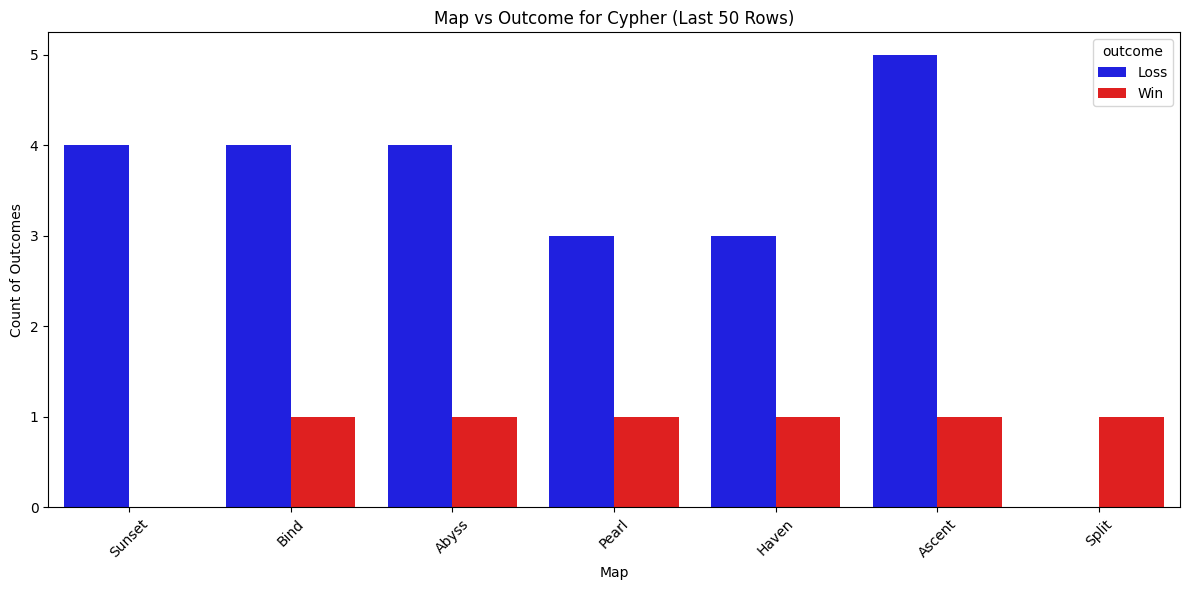

In [45]:
# Select the last 50 rows, then filter for Cypher
df_tail = df.tail(50)
df_cypher = df_tail[df_tail['agent'] == 'Cypher']

# Create the graph
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_cypher,
    x='map',
    hue='outcome',
    palette={'Loss': 'blue',
            'Win': 'red',
            'Draw': 'green'
            }
)

plt.xlabel('Map')
plt.ylabel('Count of Outcomes')
plt.title('Map vs Outcome for Cypher (Last 50 Rows)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# The last 50 match of you playing Cypher shows that you keep losing majority of the time no matter the map

# Conclusion: I don't have enough dataset to give you advice on the agent you should be playing becaus you mostly played Cypher and lose